# 1015 — 明天 spot test 的蛋白稀釋表

2026-10-15 SmartDrop X 跑 Bradford-595，把所有蛋白稀釋到同一濃度。

- 資料：[`../data/assays/1015_bradford/`](../data/assays/1015_bradford/)（Excel 讀值 + 機器螢幕照片）
- `1:5` 那列 = 樣品先稀釋 5 倍再測 → 原液 = 讀值 × 5；`raw` 那列 = 原液直接測
- 每管優先用 1:5 讀值；1:5 讀不到（≤0）才用 raw
- 目標濃度 = 最稀那管的濃度往下取整，所以最稀那管幾乎不用稀釋
- Bradford 量的是**總蛋白**，不是目標蛋白

In [1]:
import re
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt

FINAL_UL = 50          # 每管最後體積 (µL)
ROUND_TO = 50          # 目標濃度往下取整到這個倍數 (µg/mL)
XLSX = '../data/assays/1015_bradford/bradford_readings.xlsx'
OUT = 'output/1015_spot_test_dilution/dilution_table.tsv'
PNG = 'output/1015_spot_test_dilution/standard_curve.png'

## 1. 檢查機器的標準曲線

機器螢幕上的方程式係數被四捨五入成 `0.00000*x^2 + 5.0E-50*x`，不能用。這裡用螢幕上的六個 standard 自己重 fit 二次曲線，確認機器給的濃度可信。

In [2]:
std_conc = np.array([0, 125, 250, 500, 750, 1000.])          # µg/mL, std_curve_table_screen.jpg
std_abs  = np.array([0.004, 0.077, 0.244, 0.412, 0.719, 1.291])  # Abs Avg
fit = np.polyfit(std_conc, std_abs, 2)
r2 = np.corrcoef(np.polyval(fit, std_conc), std_abs)[0, 1] ** 2

def conc_from_abs(a):
    roots = np.roots(fit - [0, 0, a])
    return roots[(np.isreal(roots)) & (roots.real >= 0)].real.min()

print(f'refit R² = {r2:.3f}（機器顯示 0.990）')

refit R² = 0.990（機器顯示 0.990）


## 2. 讀 Excel

In [3]:
ws = openpyxl.load_workbook(XLSX).active
num = lambda v: float(re.search(r'-?[\d.]+', str(v)).group()) if v is not None else np.nan

rows = []
for col in range(2, ws.max_column + 1, 2):        # 樣品名在第7列 B, D, F, ...
    name = ws.cell(7, col).value
    if not name:
        continue
    for r, factor in [(8, 5), (9, 1)]:             # 第8列 = 1:5, 第9列 = raw
        rows.append(dict(sample=name, dilution=factor,
                         reading=num(ws.cell(r, col).value),
                         absorbance=num(ws.cell(r, col + 1).value)))
reads = pd.DataFrame(rows).dropna(subset=['reading'])
reads['refit'] = [conc_from_abs(a) if c > 0 else np.nan for a, c in zip(reads.absorbance, reads.reading)]
reads['stock_ug_ml'] = reads.reading * reads.dilution
reads

,sample,dilution,reading,absorbance,refit,stock_ug_ml
0,cds12+,5,401.421,0.299,394.912527,2007.105
2,cds12-,5,694.567,0.674,683.910224,3472.835
4,e1+,5,0.000,0.037,NaN,0.000
6,e40+,5,664.657,0.627,653.270667,3323.285
8,e40-,5,0.000,-0.138,NaN,0.000
9,e40-,1,461.272,0.360,451.152692,461.272
10,e281+,5,479.966,0.380,468.514200,2399.830
13,e281-,1,364.497,0.265,360.985068,364.497


In [4]:
ok = reads[reads.reading > 0]
dev = ((ok.refit - ok.reading) / ok.reading).abs().max()
assert dev < 0.05, dev
print(f'機器讀值 vs 自己 refit：最大差 {dev:.1%} → 機器濃度可用')

機器讀值 vs 自己 refit：最大差 2.4% → 機器濃度可用


## 3. 標準曲線

黑方塊 = standard，線 = 二次 refit，彩色點 = 樣品（量到的那管：1:5 稀釋後或 raw）。讀不到的（讀值 0）畫在左邊 x = 0。

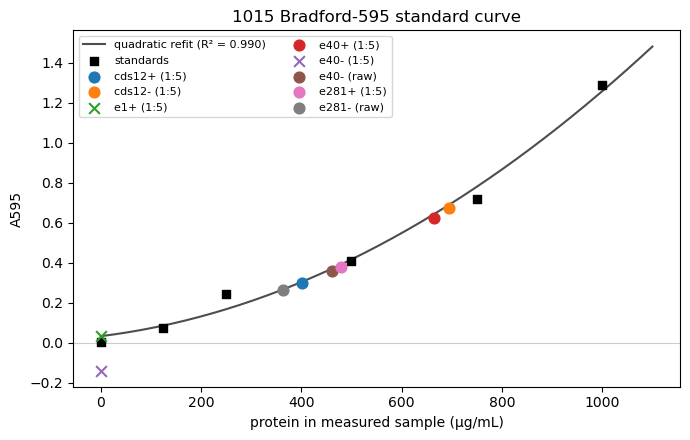

In [5]:
xs = np.linspace(0, 1100, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xs, np.polyval(fit, xs), color='0.3', lw=1.5, label=f'quadratic refit (R² = {r2:.3f})')
ax.scatter(std_conc, std_abs, color='k', marker='s', s=36, zorder=3, label='standards')
for (name, d), g in reads.groupby(['sample', 'dilution'], sort=False):
    tag = '1:5' if d == 5 else 'raw'
    marker = 'o' if g.reading.iloc[0] > 0 else 'x'
    ax.scatter(g.reading, g.absorbance, marker=marker, s=60, zorder=4, label=f'{name} ({tag})')
ax.axhline(0, color='0.8', lw=0.8)
ax.set(xlabel='protein in measured sample (µg/mL)', ylabel='A595', title='1015 Bradford-595 standard curve')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(PNG, dpi=200)
plt.show()

## 4. 每管的原液濃度

讀值 = 0 代表吸光度低於標準曲線（`e1+` 的 1:5 吸光度 0.037，`e40-` 的 1:5 是負的），這種讀值不算數。

In [6]:
good = reads[reads.reading > 0].sort_values('dilution', ascending=False)   # 1:5 優先
stock = good.groupby('sample', sort=False).first()[['dilution', 'stock_ug_ml']]
bad = sorted(set(reads['sample']) - set(stock.index))
print('沒辦法定量，不納入:', bad or '無')
stock

沒辦法定量，不納入: ['e1+']


,dilution,stock_ug_ml
sample,,
cds12+,5,2007.105
cds12-,5,3472.835
e40+,5,3323.285
e281+,5,2399.830
e40-,1,461.272
e281-,1,364.497


## 5. 計算

C₁V₁ = C₂V₂ → 原液體積 = 目標濃度 × 每管體積 / 原液濃度，剩下補 buffer。

In [7]:
target = np.floor(stock.stock_ug_ml.min() / ROUND_TO) * ROUND_TO
order = list(dict.fromkeys(reads['sample']))          # Excel 上的順序
table = stock.reindex([s for s in order if s in stock.index])
table['protein_uL'] = (target * FINAL_UL / table.stock_ug_ml).round(1)
table['buffer_uL'] = (FINAL_UL - table.protein_uL).round(1)
table.to_csv(OUT, sep='\t')
print(f'目標濃度 {target:.0f} µg/mL，每管 {FINAL_UL} µL')
table

目標濃度 350 µg/mL，每管 50 µL


,dilution,stock_ug_ml,protein_uL,buffer_uL
sample,,,,
cds12+,5,2007.105,8.7,41.3
cds12-,5,3472.835,5.0,45.0
e40+,5,3323.285,5.3,44.7
e40-,1,461.272,37.9,12.1
e281+,5,2399.830,7.3,42.7
e281-,1,364.497,48.0,2.0


## 6. Dilution 步驟（照這張做）

In [8]:
steps = table.reset_index()[['sample', 'buffer_uL', 'protein_uL']]
steps.index = range(1, len(steps) + 1)
steps.index.name = '管'
steps.columns = ['樣品', '① buffer (µL)', '② 蛋白原液 (µL)']
print(f'目標 {target:.0f} µg/mL × {FINAL_UL} µL/管')
steps

目標 350 µg/mL × 50 µL/管


,樣品,① buffer (µL),② 蛋白原液 (µL)
管,,,
1,cds12+,41.3,8.7
2,cds12-,45.0,5.0
3,e40+,44.7,5.3
4,e40-,12.1,37.9
5,e281+,42.7,7.3
6,e281-,2.0,48.0


1. 照上表順序標好管子，每管先加 ① buffer。
2. 再加 ② 蛋白原液，輕輕 pipette 混勻，放冰上。
3. **buffer 要用蛋白本身所在的 buffer**（lysis buffer / 洗脫 buffer），不要用水，不然各管 buffer 成分不同。
4. 濃的那幾管只取 5–9 µL 原液，用 P10/P20 吸，誤差才小。
5. `e281-` 最稀，要用掉 48 µL，確定那管夠量。

**注意**
- `e1+` 1:5 讀不到，原液可能 < ~50 µg/mL，不在表裡；要納入的話先用 raw 再測一次，濃度 ≥ 目標才能加進來。
- 目前蛋白都沒有成功純化（1010 Ni-NTA 失敗），這些是總蛋白濃度，等量的總蛋白不代表等量的目標蛋白。